In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.preprocessing import image
from tensorflow.keras.utils import plot_model
from pathlib import Path
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import tensorflow as tf
import pandas as pd
import numpy as np
import cv2
import os

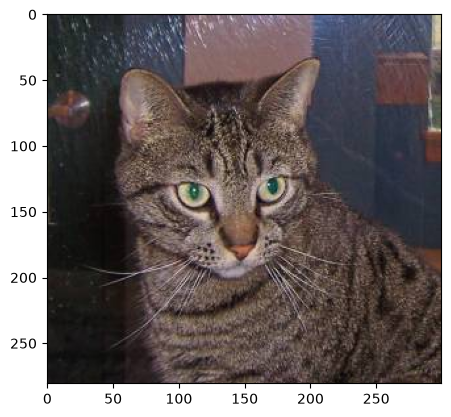

In [2]:
img = image.load_img('Dataset/train/Cat/1.JPG')
plt.imshow(img)

In [3]:

cv2.imread('Dataset/train/Cat/1.JPG').shape  #height, width, and channels of image

(281, 300, 3)

In [4]:
train = ImageDataGenerator(
    rescale=1/255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)
validation = ImageDataGenerator(rescale=1/255)

In [5]:
train_dataset = train.flow_from_directory(
    'Dataset/train/',
    target_size=(224, 224),
    classes=['Cat', 'Cow', 'Crocodile', 'Dog', 'Snake'],
    batch_size=20,
    class_mode='categorical',
    shuffle=True
)

validation_dataset = validation.flow_from_directory(
    'Dataset/validation/',
    target_size=(224, 224),
    classes=['Cat', 'Cow', 'Crocodile', 'Dog', 'Snake'],
    batch_size=20,
    class_mode='categorical',
    shuffle=False
)

Found 1000 images belonging to 5 classes.
Found 150 images belonging to 5 classes.


In [6]:
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.Rescaling(2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(5, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

C:\Users\darac\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    metrics=['accuracy']
)

In [8]:
callbacks = [
    tf.keras.callbacks.CSVLogger("history.csv"),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=4,
        restore_best_weights=True
    )
]

model_fit = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=callbacks,
    shuffle=True
)

_, accuracy = model.evaluate(validation_dataset)
print(f"Validation accuracy: {accuracy * 100:.2f}%")

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 177ms/step - accuracy: 0.3100 - loss: 0.5397 - val_accuracy: 0.4200 - val_loss: 0.4455
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step - accuracy: 0.5140 - loss: 0.4006 - val_accuracy: 0.6400 - val_loss: 0.3049
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 151ms/step - accuracy: 0.7100 - loss: 0.2830 - val_accuracy: 0.6000 - val_loss: 0.3023
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 144ms/step - accuracy: 0.8340 - loss: 0.1860 - val_accuracy: 0.9133 - val_loss: 0.1247
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.9200 - loss: 0.1097 - val_accuracy: 0.9867 - val_loss: 0.0516
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 142ms/step - accuracy: 0.9650 - loss: 0.0589 - val_accuracy: 0.9867 - val_loss: 0.0420
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 145ms/step - accuracy: 0.9850 - loss: 0.0385 - val_accuracy: 1.0000 - val_loss: 0.0152
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - accuracy: 0.9940 - loss: 0.0143 - val_accuracy: 1

In [9]:
his = pd.read_csv('history.csv') 
his.head(10)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.310,0.539675,0.420000,0.445510
1,1,0.514,0.400632,0.640000,0.304910
2,2,0.710,0.282994,0.600000,0.302340
3,3,0.834,0.186032,0.913333,0.124748
4,4,0.920,0.109664,0.986667,0.051578
5,5,0.965,0.058875,0.986667,0.042043
6,6,0.985,0.038514,1.000000,0.015205
7,7,0.994,0.014281,1.000000,0.010953
8,8,0.994,0.018701,0.986667,0.027692
9,9,0.990,0.021760,1.000000,0.006198


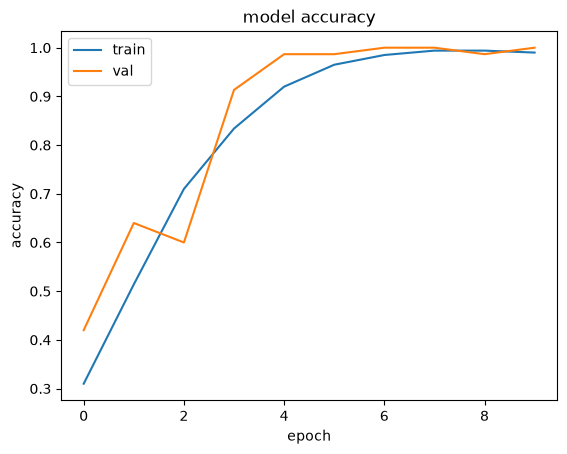

In [10]:

plt.plot(model_fit.history['accuracy'])
plt.plot(model_fit.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

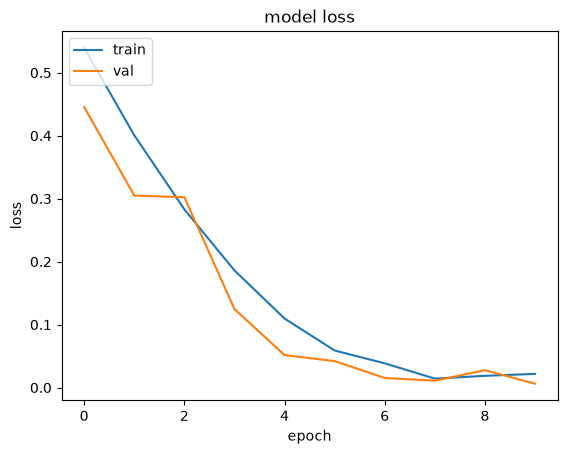

In [11]:
plt.plot(model_fit.history['loss'])
plt.plot(model_fit.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [12]:
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add traces
fig.add_trace(
    go.Scatter( y=model_fit.history['val_loss'], name="val_loss"),
    secondary_y=False)

fig.add_trace(
    go.Scatter( y=model_fit.history['loss'], name="loss"),
    secondary_y=False)

fig.add_trace(
    go.Scatter( y=model_fit.history['val_accuracy'], name="val_accuracy"),
    secondary_y=True)

fig.add_trace(
    go.Scatter( y=model_fit.history['accuracy'], name="accuracy"),
    secondary_y=True)

# Add figure title
fig.update_layout(
    title_text="Loss/Accuracy of Conv2D Model")

# Set x-axis title
fig.update_xaxes(title_text="Number of Epochs")

# Set y-axes titles
fig.update_yaxes(title_text="<b>primary</b> Loss", secondary_y=False)
fig.update_yaxes(title_text="<b>secondary</b> Accuracy", secondary_y=True)

fig.show()



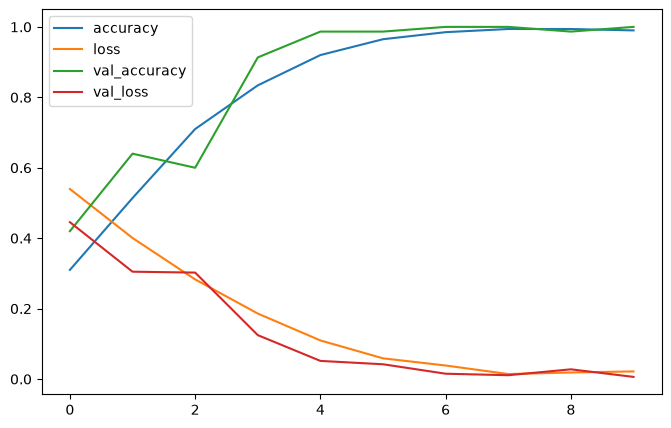

In [13]:
pd.DataFrame(model_fit.history).plot(figsize=(8,5))
plt.show()

In [14]:
model.summary() #Detail of model



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 198, 198, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 99, 99, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 97, 97, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 46, 46, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 33856)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      17,334,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,082,801 (198.68 MB)

 Trainable params: 17,360,933 (66.23 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,721,868 (132.45 MB)

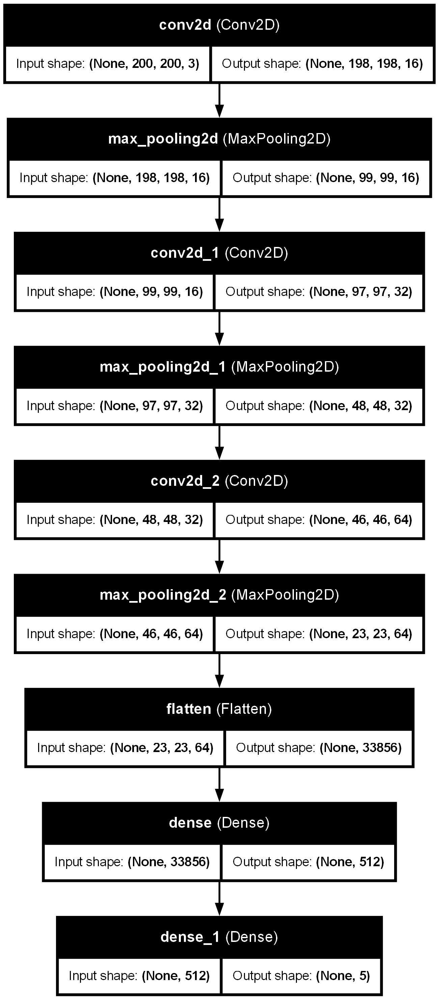

In [15]:

plot_model(model, to_file = 'convlstm_model_structure_plot.png', show_shapes = True, show_layer_names = True)

In [16]:
import os

# Ensure the 'models' directory exists
os.makedirs('models', exist_ok=True)

# Save the model
model.save('models/CNN_predict_model.h5')
print("Model saved successfully!")


Model saved successfully!


In [17]:
validation_dataset.class_indices

{'Cat': 0, 'Cow': 1, 'Crocodile': 2, 'Dog': 3, 'Snake': 4}

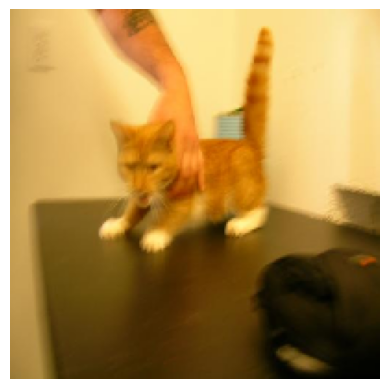

File: 0.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.79% confidence)



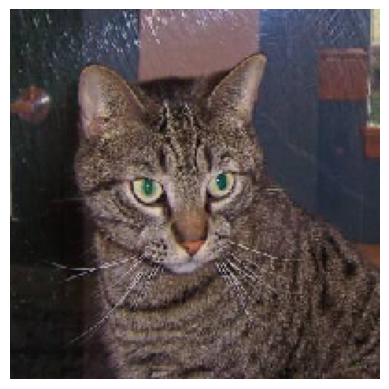

File: 1.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.99% confidence)



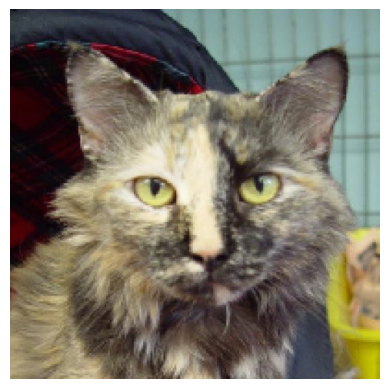

File: 10.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



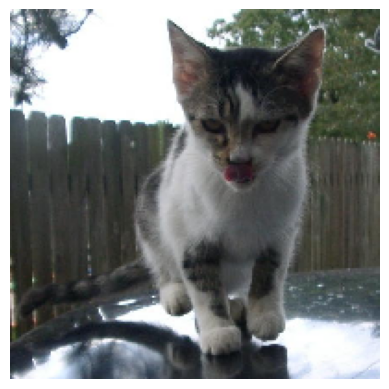

File: 11.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



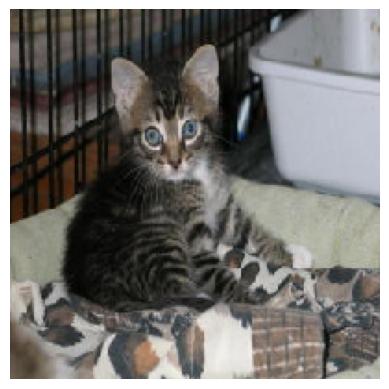

File: 12.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



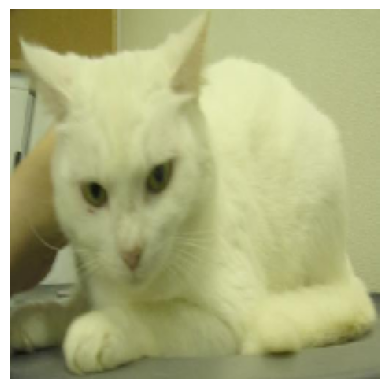

File: 13.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.23% confidence)



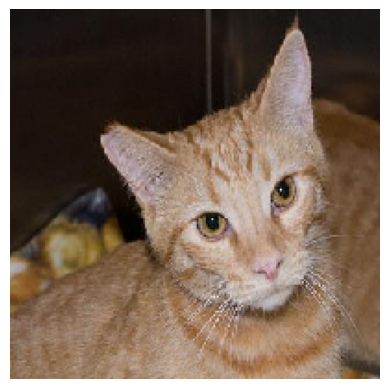

File: 14.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



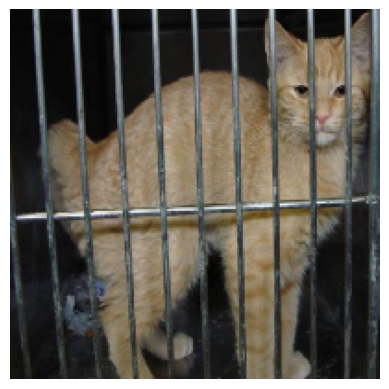

File: 15.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



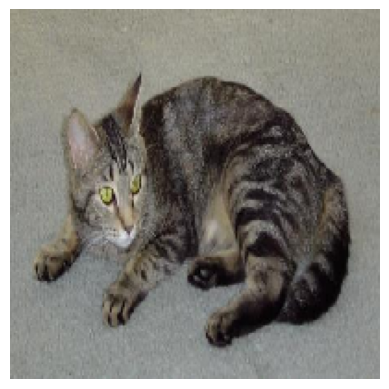

File: 16.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.67% confidence)



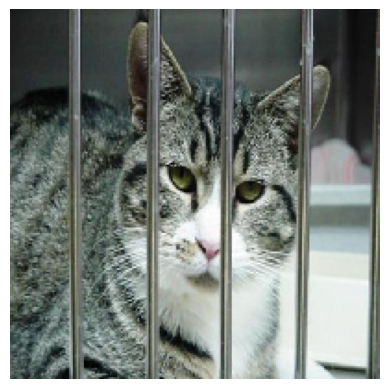

File: 17.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.99% confidence)



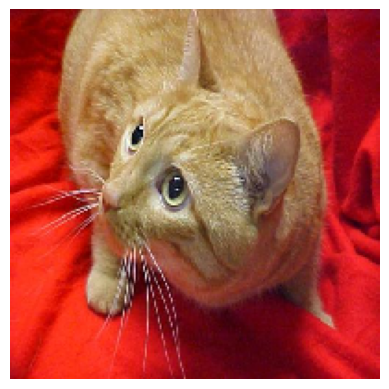

File: 18.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.99% confidence)



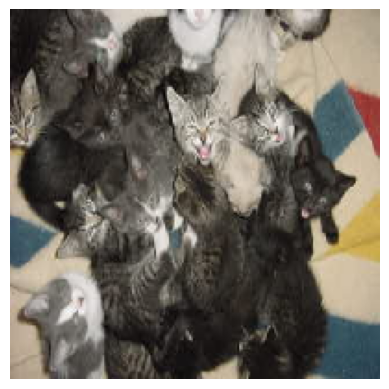

File: 19.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



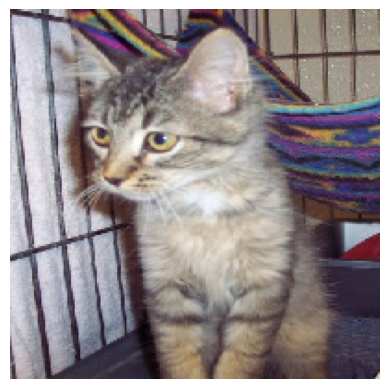

File: 2.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



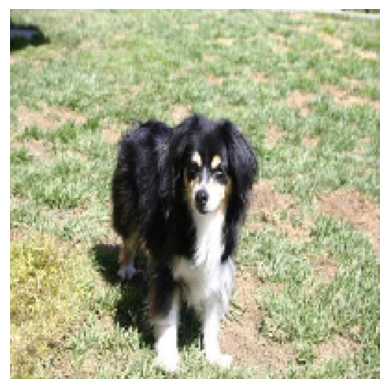

File: 20.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.89% confidence)



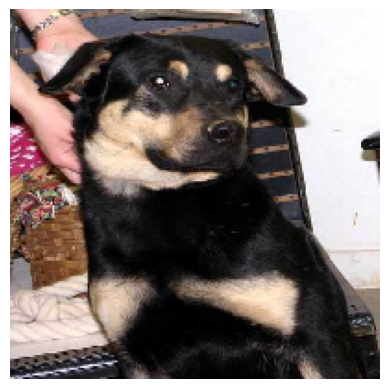

File: 21.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



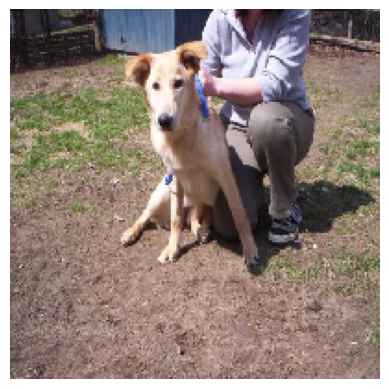

File: 22.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



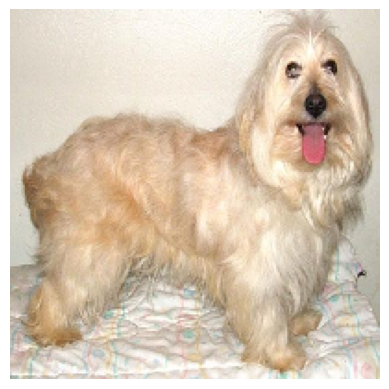

File: 23.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.95% confidence)



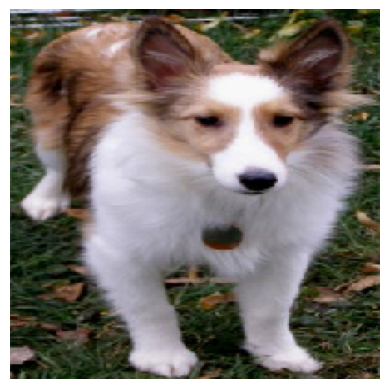

File: 24.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



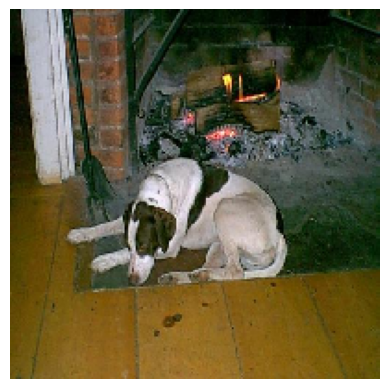

File: 25.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



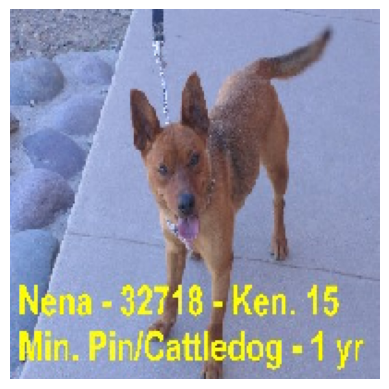

File: 26.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.99% confidence)



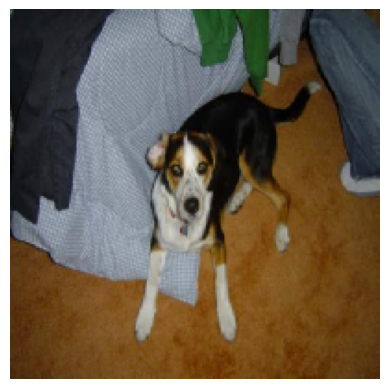

File: 27.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



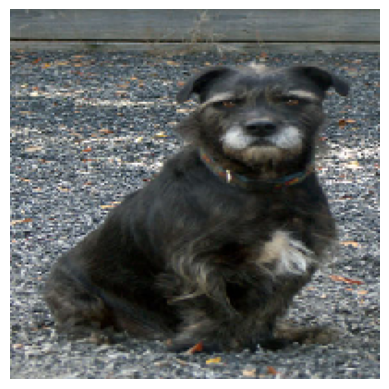

File: 28.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



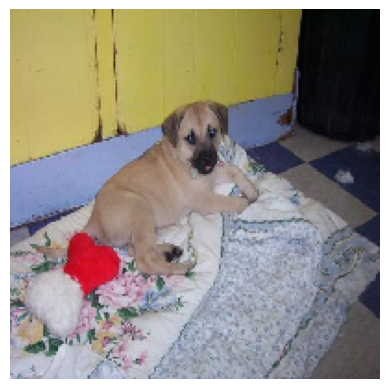

File: 29.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.99% confidence)



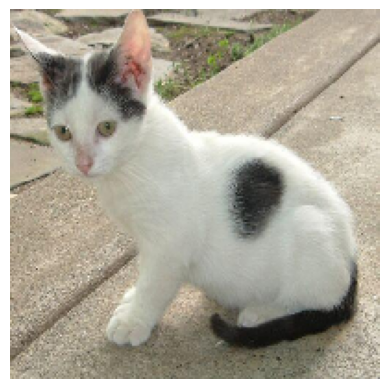

File: 3.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



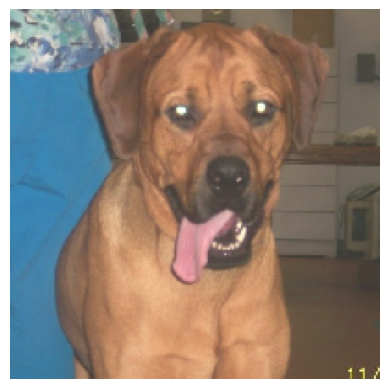

File: 30.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



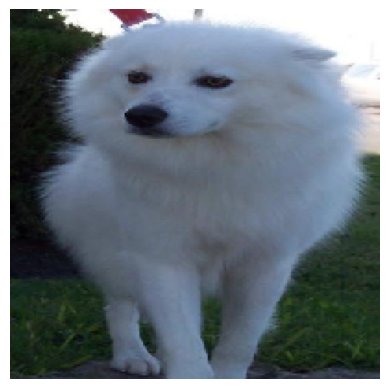

File: 31.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



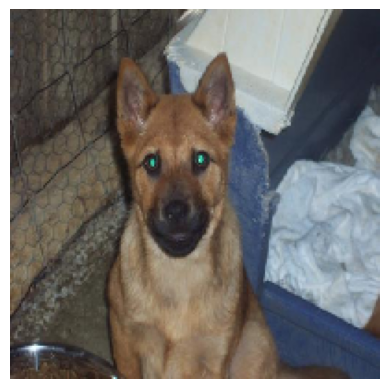

File: 32.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.94% confidence)



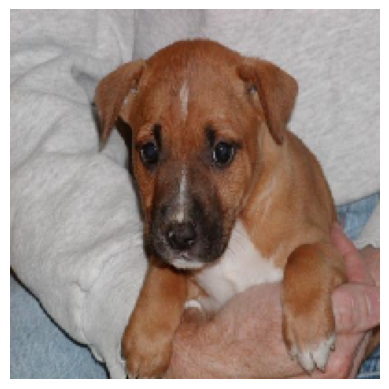

File: 33.jpg -> This is Dog 🐶🐶🐶🐶🐶 (99.96% confidence)



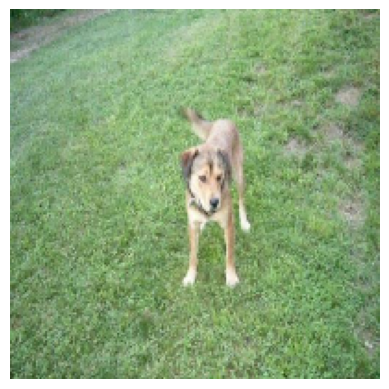

File: 34.jpg -> This is Dog 🐶🐶🐶🐶🐶 (93.11% confidence)



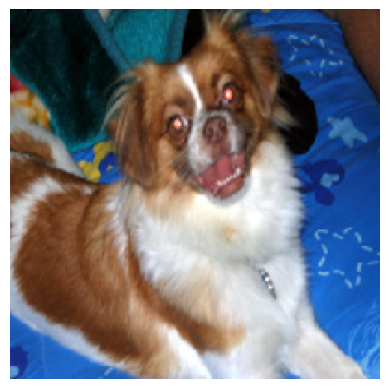

File: 35.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



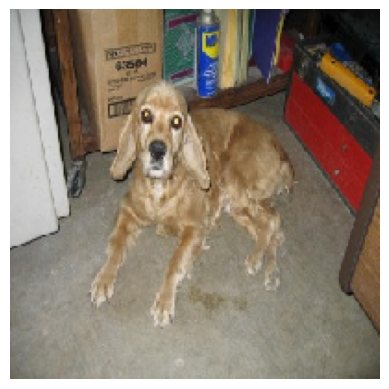

File: 36.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



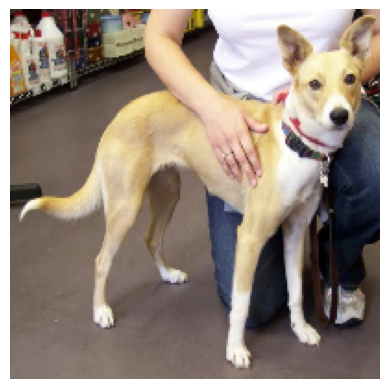

File: 37.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



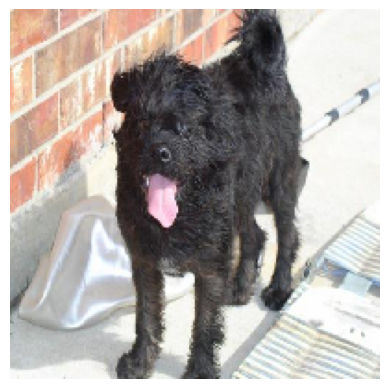

File: 38.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



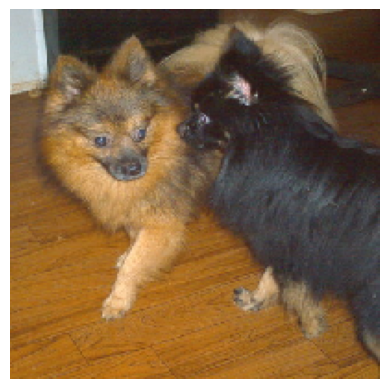

File: 39.jpg -> This is Dog 🐶🐶🐶🐶🐶 (100.00% confidence)



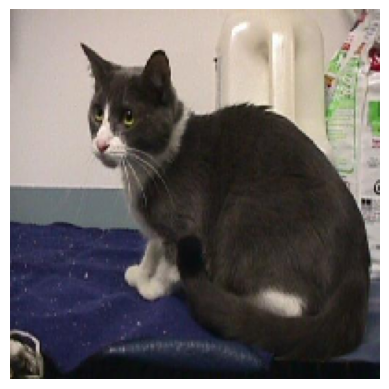

File: 4.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



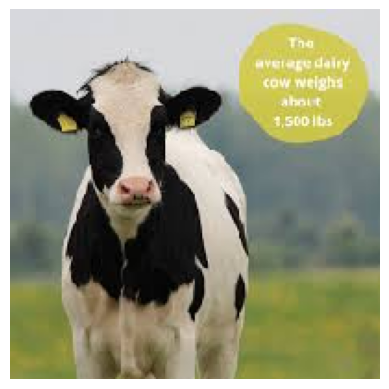

File: 40.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



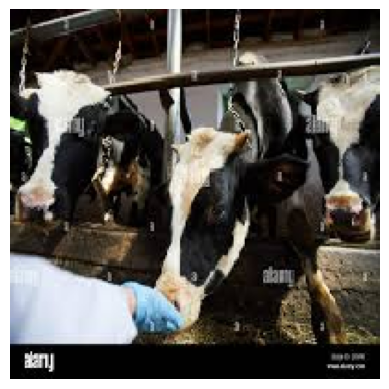

File: 41.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



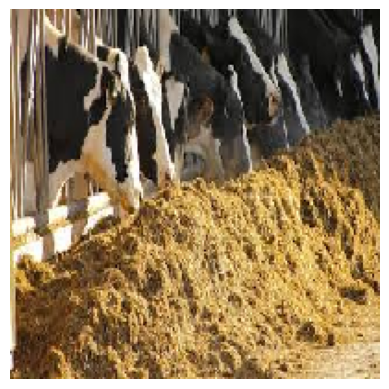

File: 42.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



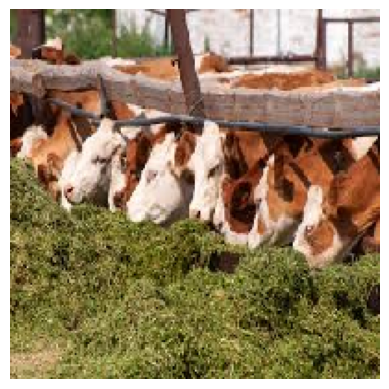

File: 43.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



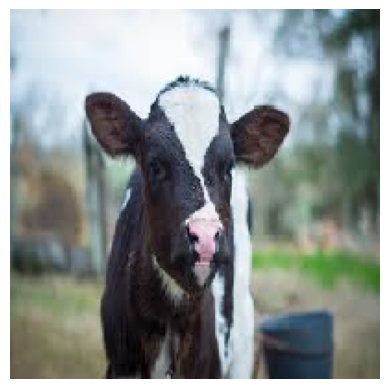

File: 44.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



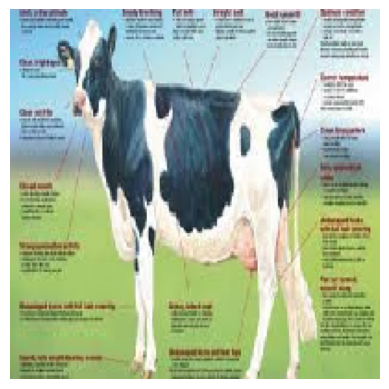

File: 45.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



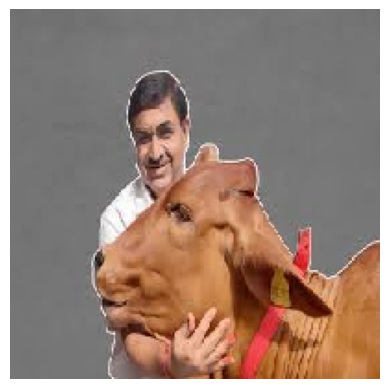

File: 46.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



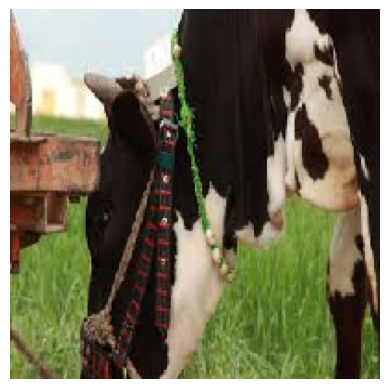

File: 47.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



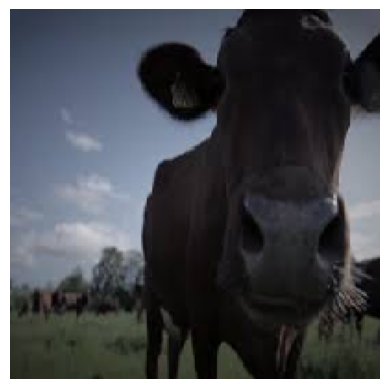

File: 48.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



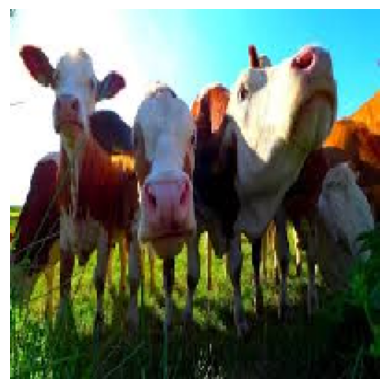

File: 49.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



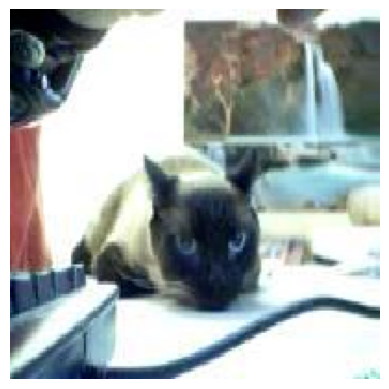

File: 5.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



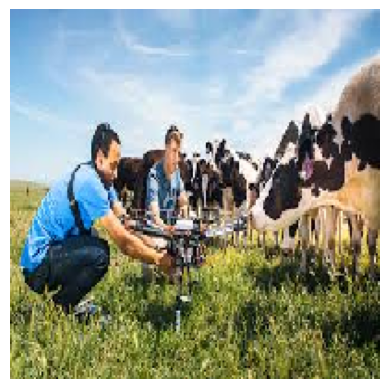

File: 50.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



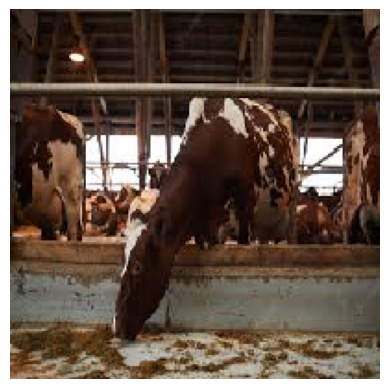

File: 51.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



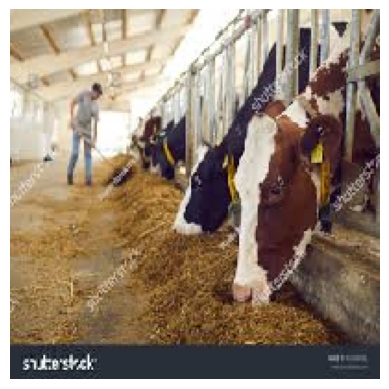

File: 52.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



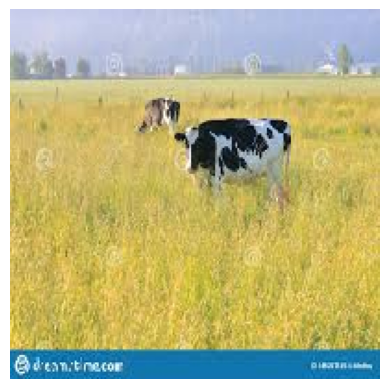

File: 53.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



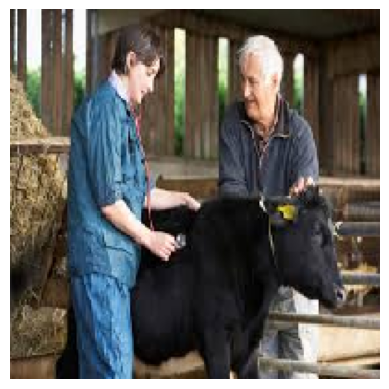

File: 54.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



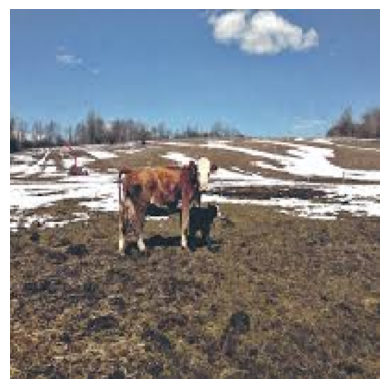

File: 55.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



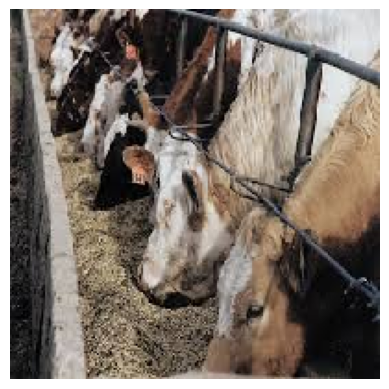

File: 56.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



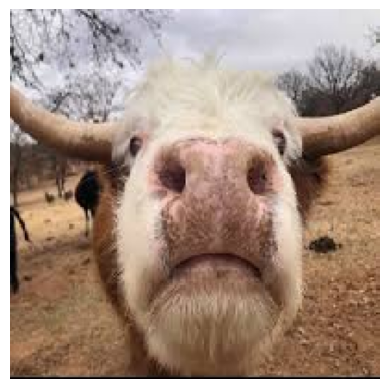

File: 57.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



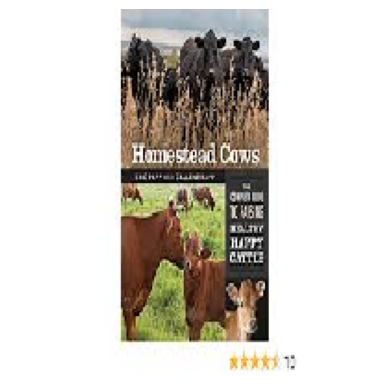

File: 58.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



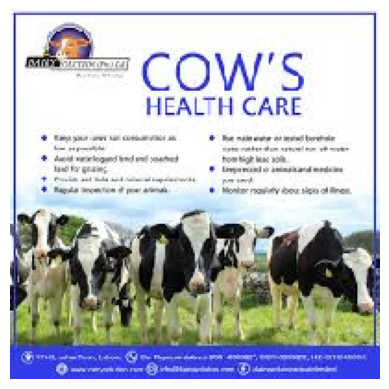

File: 59.jpg -> This is Cow 🐄🐄🐄🐄🐄 (100.00% confidence)



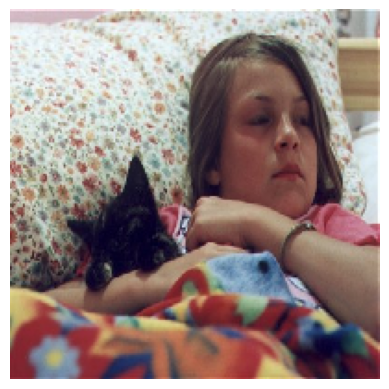

File: 6.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.99% confidence)



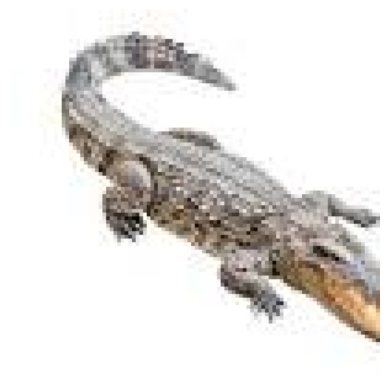

File: 60.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



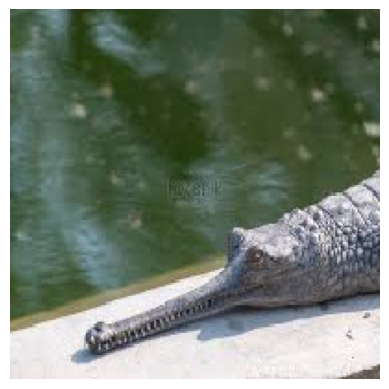

File: 61.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (99.95% confidence)



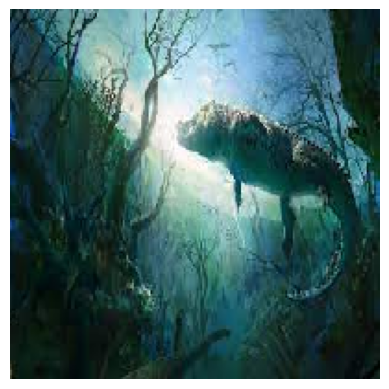

File: 62.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (99.99% confidence)



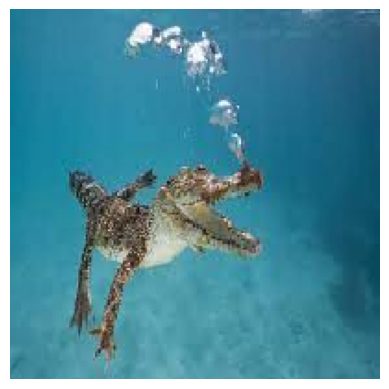

File: 63.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



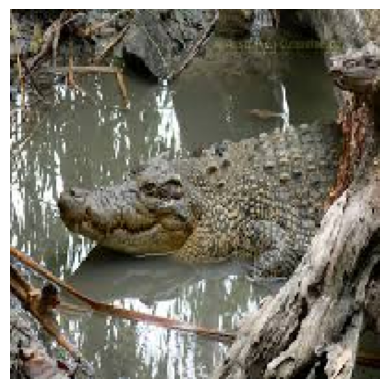

File: 64.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



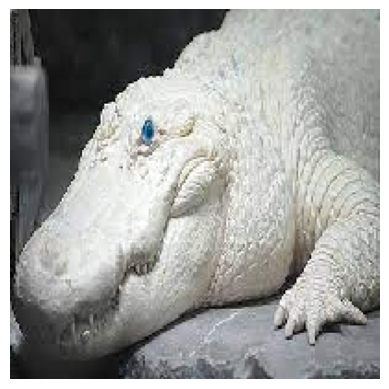

File: 65.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



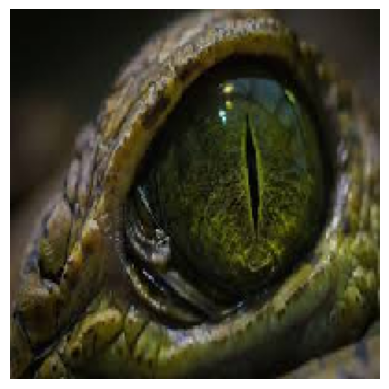

File: 66.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



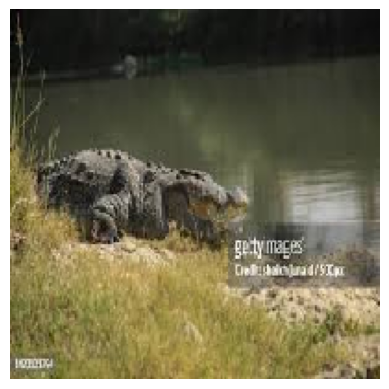

File: 67.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



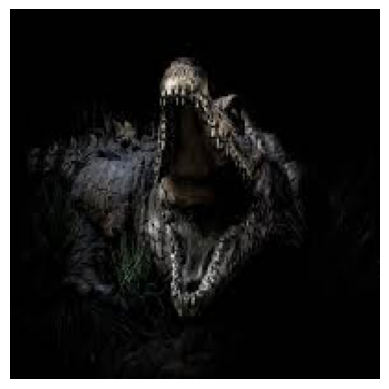

File: 68.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



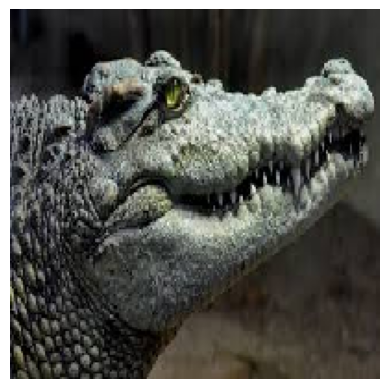

File: 69.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



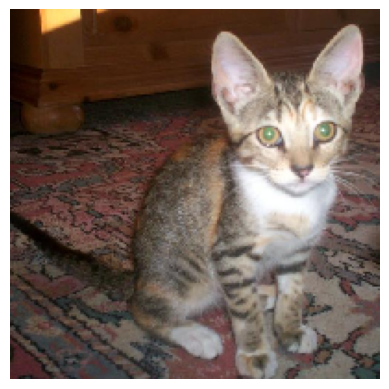

File: 7.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



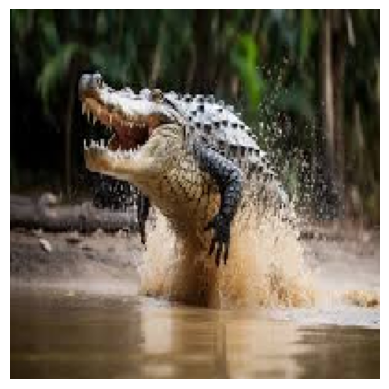

File: 70.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



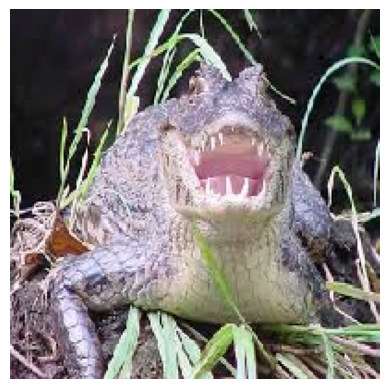

File: 71.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



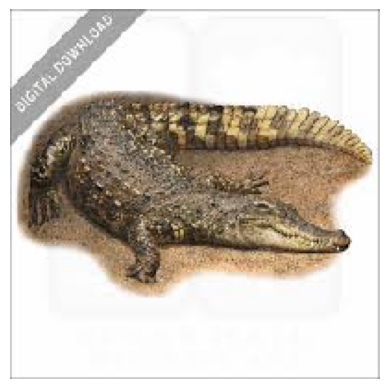

File: 72.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



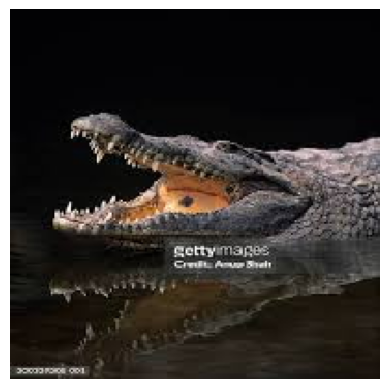

File: 73.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



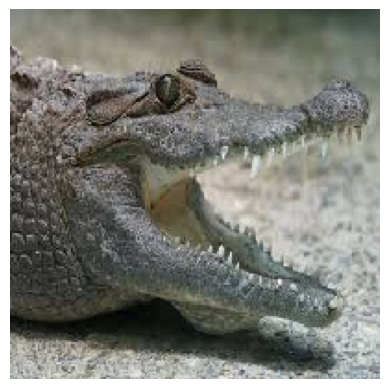

File: 74.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (99.71% confidence)



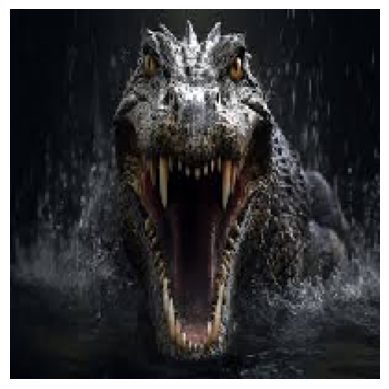

File: 75.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



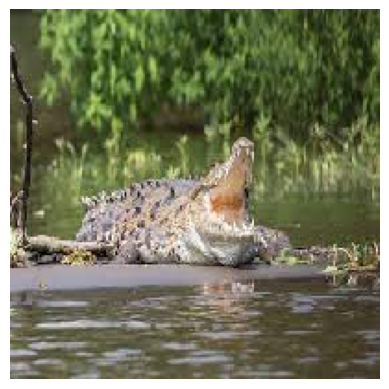

File: 76.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (99.99% confidence)



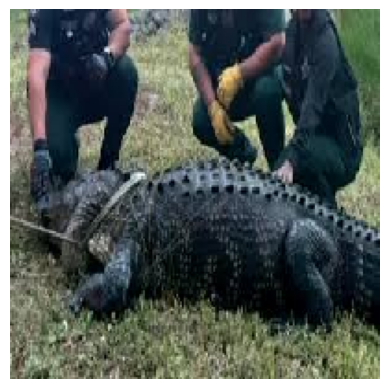

File: 77.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



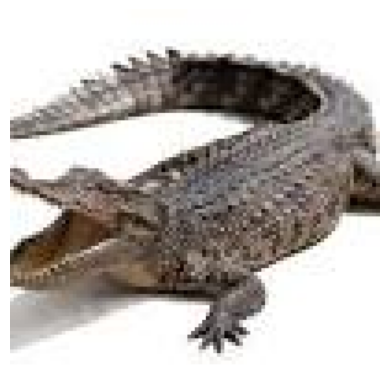

File: 78.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



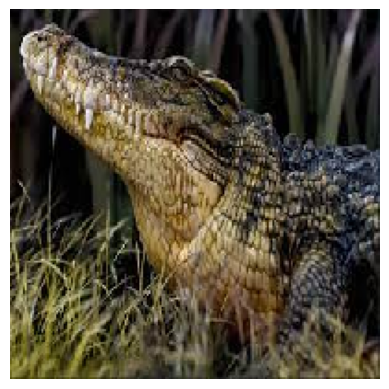

File: 79.jpg -> This is Crocodile 🐊🐊🐊🐊🐊 (100.00% confidence)



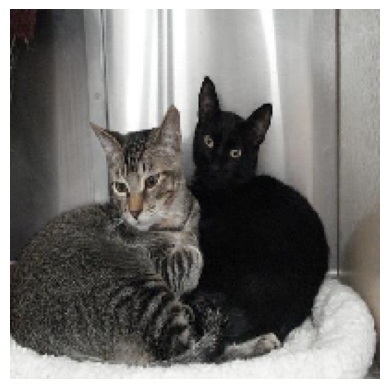

File: 8.jpg -> This is Cat 🐈🐈🐈🐈🐈 (100.00% confidence)



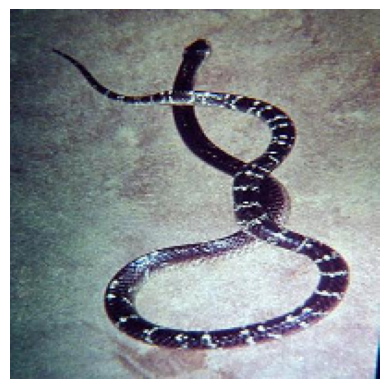

File: 80.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



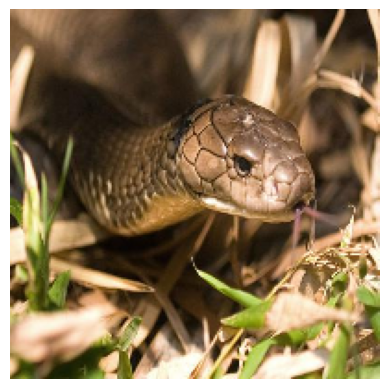

File: 81.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



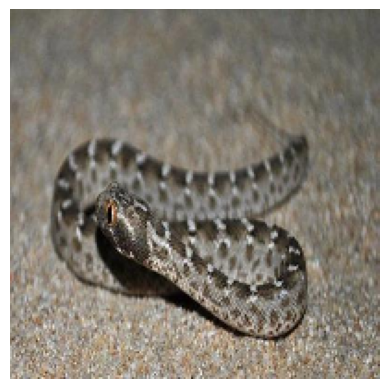

File: 82.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



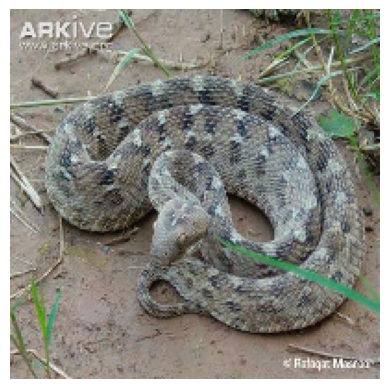

File: 83.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



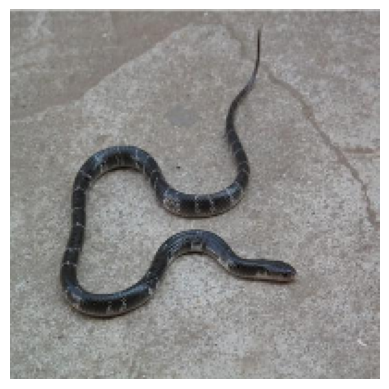

File: 84.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



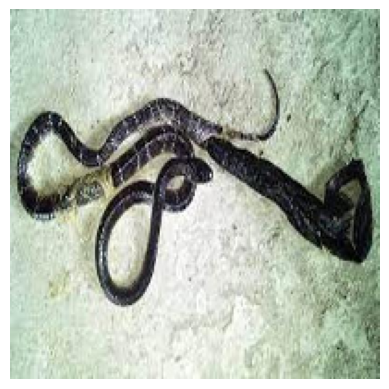

File: 85.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



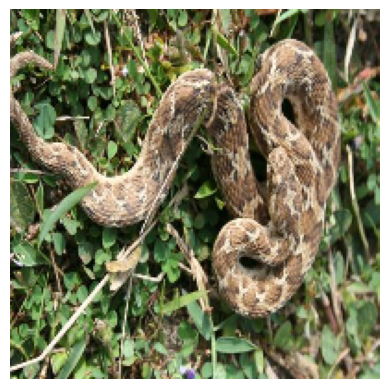

File: 86.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



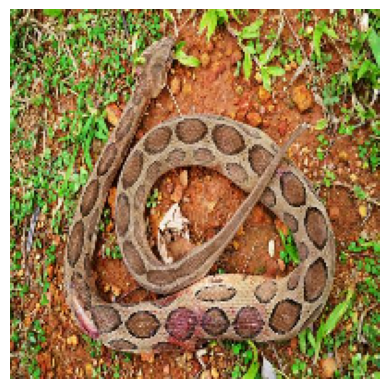

File: 87.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



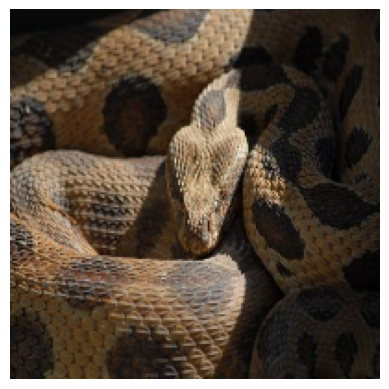

File: 88.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



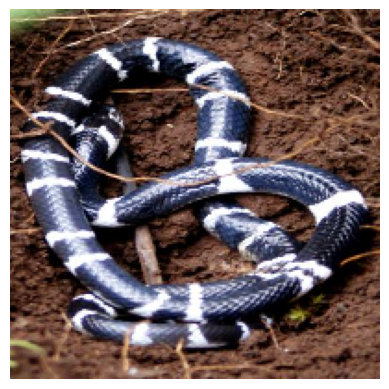

File: 89.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



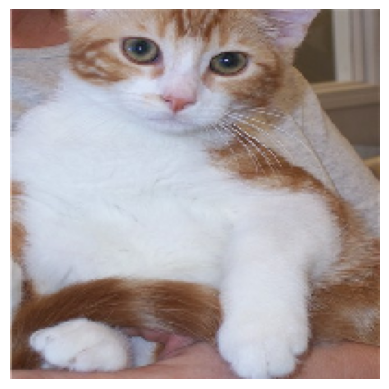

File: 9.jpg -> This is Cat 🐈🐈🐈🐈🐈 (99.98% confidence)



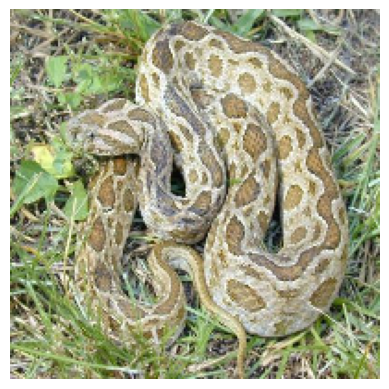

File: 90.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



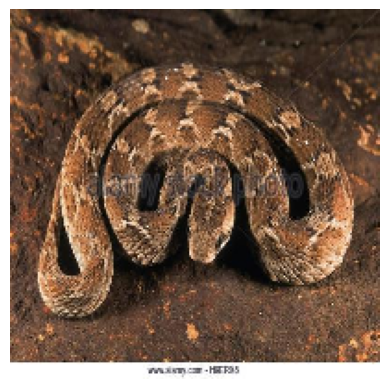

File: 91.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



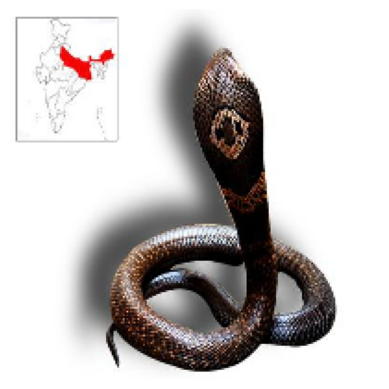

File: 92.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



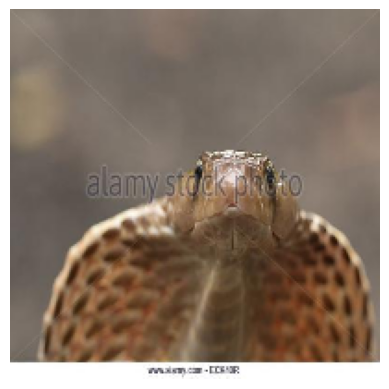

File: 93.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



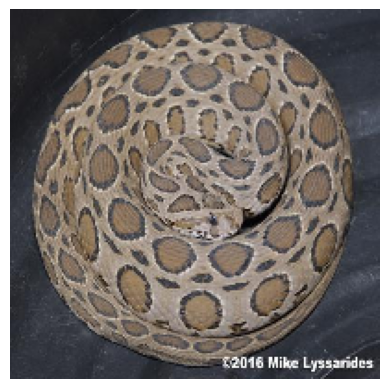

File: 94.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



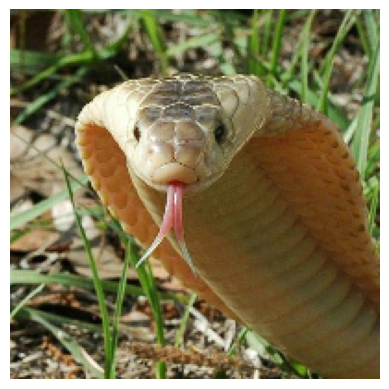

File: 95.jpg -> This is Snake 🐍🐍🐍🐍🐍 (99.99% confidence)



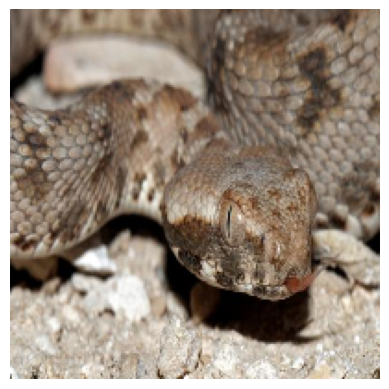

File: 96.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



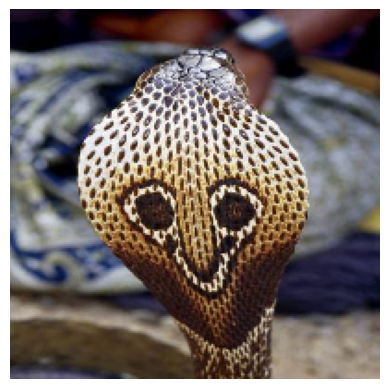

File: 97.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



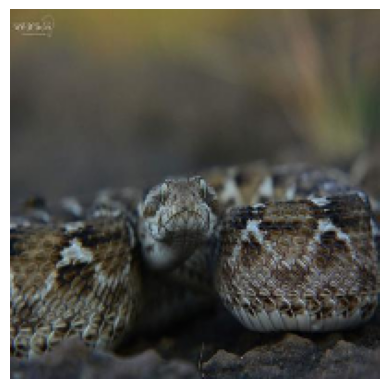

File: 98.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



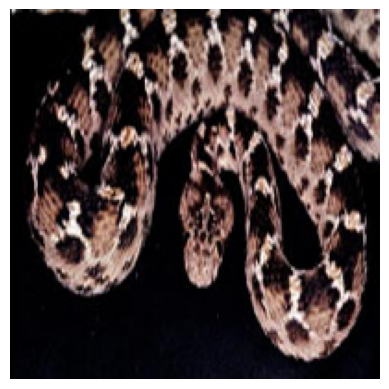

File: 99.jpg -> This is Snake 🐍🐍🐍🐍🐍 (100.00% confidence)



In [18]:
dir_path = 'Dataset/test'

# Emoji dictionary for the 5 classes
emoji_dict = {
    'Cat': '🐈',
    'Cow': '🐄',
    'Crocodile': '🐊',
    'Dog': '🐶',
    'Snake': '🐍'
}

# Reverse class indices to get {0: 'Cat', 1: 'Cow', 2: 'Crocodile', 3: 'Dog', 4: 'Snake'}
idx_to_class = {v: k for k, v in validation_dataset.class_indices.items()}

for i in os.listdir(dir_path):
    img_path = os.path.join(dir_path, i)
    
    # Load and show the image
    img = image.load_img(img_path, target_size=(224, 224))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    
    # Preprocess image
    X = image.img_to_array(img)
    X = X / 255.0                           # IMPORTANT: Normalize pixel values (same as training rescale=1/255)
    X = np.expand_dims(X, axis=0)           # Shape: (1, 224, 224, 3)
    
    # Predict
    val = model.predict(X, verbose=0)
    pred_idx = np.argmax(val, axis=-1)[0]   # Index of highest probability
    confidence = np.max(val) * 100          # Confidence percentage
    
    class_name = idx_to_class[pred_idx]
    emoji = emoji_dict.get(class_name, '')
    
    print(f"File: {i} -> This is {class_name} {emoji * 5} ({confidence:.2f}% confidence)\n")

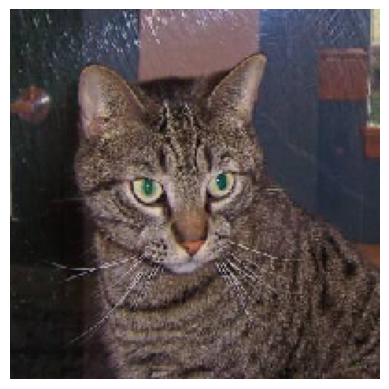

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 544ms/step
Prediction: Cat (99.98999786376953% confidence)


In [19]:
# Path of the image you want to test
path = "Dataset/test/1.JPG"
img = image.load_img(path, target_size=(224, 224))
plt.imshow(img)
plt.axis('off')
plt.show()

# Preprocess image
X = image.img_to_array(img)
X = X / 255.0                          # Normalize (must match training rescale=1/255)
images = np.expand_dims(X, axis=0)     # Shape: (1, 224, 224, 3)

# Predict
val = model.predict(images)
pred_idx = np.argmax(val, axis=-1)[0]  # Get index of highest probability (0 to 4)
confidence = np.max(val) * 100         # Confidence score for this image

# Map class index to class name
labels = {v: k for k, v in validation_dataset.class_indices.items()}
picture = labels[pred_idx]

print(f"Prediction: {picture} ({round(confidence, 2)}% confidence)")

In [20]:
from tensorflow.keras.models import load_model
new_model = load_model('models/CNN_predict_model.h5')

In [21]:
new_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 198, 198, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 99, 99, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 97, 97, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 46, 46, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 33856)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      17,334,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,360,935 (66.23 MB)

 Trainable params: 17,360,933 (66.23 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)